# 01 · Data Understanding
**CardioInsight – Heart Disease Risk Analysis** · Module 1 (Introduction to Data Science)

In this notebook we get to know the dataset before doing any analysis: where it comes from, how big it is,
what each column means, which columns are numbers and which are categories, and how many patients have heart disease.

## The CRISP-DM process and where each notebook fits
**CRISP-DM** (Cross-Industry Standard Process for Data Mining) is the standard 6-step life cycle of a data science project.
This project follows it step by step:

| CRISP-DM step | What it means | Where in this project |
|---|---|---|
| 1. Business understanding | What problem are we solving and why? | This notebook (problem statement) + README |
| 2. Data understanding | Explore the data: size, types, quality, balance | **01** Data understanding, **02** Descriptive statistics, **03** Correlation |
| 3. Data preparation | Clean, fix missing values and outliers | **04** Inferential statistics (feature relevance), **05** Outliers, **06** Missing-value imputation |
| 4. Modelling | Train machine learning models | **07** Model building |
| 5. Evaluation | Check models with proper validation; think about risks | **07** Validation, **08** Ethics & limitations |
| 6. Deployment | Make the model usable | Streamlit app `CardioInsight` (runs locally) |

**Business problem:** heart disease is the leading cause of death worldwide. Given routine clinical measurements
(age, blood pressure, cholesterol, ECG results, exercise test results …), can we flag patients who are likely to have
heart disease so a doctor can prioritise further tests?

### Setup
We import the usual libraries plus our own `src/` package. `src` holds all reusable code (statistics formulas, outlier detectors, model pipelines, plot styles) so the notebooks and the Streamlit app use exactly the same logic. The random seed is fixed to **42** so every run gives the same numbers.

In [1]:
import sys
from pathlib import Path

# Make the project root importable so we can use our own src/ package
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

from src import config as C
from src import data, plots
plots.set_style()
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
np.random.seed(C.RANDOM_STATE)

## 1. Dataset source
The data is the **Heart Failure Prediction Dataset** published on Kaggle by *fedesoriano* (2021).
It combines five older heart disease datasets from hospitals in the USA and Europe (Cleveland, Hungary, Switzerland,
Long Beach VA and the Statlog dataset). After removing duplicate patients, **918 patients** remain.
Each row is one patient and the last column, `HeartDisease`, is the **target** we want to predict (1 = has heart disease, 0 = normal).

Let us load the raw CSV file and look at the first few rows.

In [2]:
df = data.load_raw()
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (918, 12)


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.000,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.000,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.000,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.500,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.000,Up,0


## 2. Data types and what each column means
`dtypes` tells us how pandas stored each column. Below we also add a plain description of every column
and classify it as **continuous numerical**, **categorical** or **target**.

In [3]:
descriptions = {
    "Age": "Age of the patient [years]",
    "Sex": "Sex of the patient [M = male, F = female]",
    "ChestPainType": "TA = typical angina, ATA = atypical angina, NAP = non-anginal pain, ASY = asymptomatic",
    "RestingBP": "Resting blood pressure [mm Hg]",
    "Cholesterol": "Serum cholesterol [mg/dl]",
    "FastingBS": "Fasting blood sugar [1 if > 120 mg/dl, else 0]",
    "RestingECG": "Resting ECG: Normal, ST (ST-T wave abnormality), LVH (left ventricular hypertrophy)",
    "MaxHR": "Maximum heart rate achieved in exercise test [bpm]",
    "ExerciseAngina": "Exercise-induced angina [Y = yes, N = no]",
    "Oldpeak": "ST depression during exercise vs rest [mm]",
    "ST_Slope": "Slope of the peak exercise ST segment [Up, Flat, Down]",
    "HeartDisease": "Target: 1 = heart disease, 0 = normal",
}

def kind(col):
    if col == C.TARGET:
        return "Target (binary)"
    return "Continuous numerical" if col in C.CONTINUOUS else "Categorical"

info = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "Feature type": [kind(c) for c in df.columns],
    "Unique values": df.nunique(),
    "Example values": [", ".join(map(str, df[c].unique()[:4])) for c in df.columns],
    "Meaning": [descriptions[c] for c in df.columns],
})
info

,dtype,Feature type,Unique values,Example values,Meaning
Age,int64,Continuous numerical,50,"40, 49, 37, 48",Age of the patient [years]
Sex,str,Categorical,2,"M, F","Sex of the patient [M = male, F = female]"
ChestPainType,str,Categorical,4,"ATA, NAP, ASY, TA","TA = typical angina, ATA = atypical angina, NA..."
RestingBP,int64,Continuous numerical,67,"140, 160, 130, 138",Resting blood pressure [mm Hg]
Cholesterol,int64,Continuous numerical,222,"289, 180, 283, 214",Serum cholesterol [mg/dl]
FastingBS,int64,Categorical,2,"0, 1","Fasting blood sugar [1 if > 120 mg/dl, else 0]"
RestingECG,str,Categorical,3,"Normal, ST, LVH","Resting ECG: Normal, ST (ST-T wave abnormality..."
MaxHR,int64,Continuous numerical,119,"172, 156, 98, 108",Maximum heart rate achieved in exercise test [...
ExerciseAngina,str,Categorical,2,"N, Y","Exercise-induced angina [Y = yes, N = no]"
Oldpeak,float64,Continuous numerical,53,"0.0, 1.0, 1.5, 2.0",ST depression during exercise vs rest [mm]


## 3. Numerical vs categorical features
* **Continuous numerical (5):** values on a measured scale where averages make sense.
* **Categorical (6):** values are labels/groups. `FastingBS` is stored as 0/1 numbers, but it is really a yes/no
  category, so we treat it as categorical.

In [4]:
print("Continuous numerical features:", C.CONTINUOUS)
print("Categorical features:          ", C.CATEGORICAL)
print("Target:                        ", C.TARGET)

Continuous numerical features: ['Age', 'RestingBP', 'Cholesterol', 'MaxHR', 'Oldpeak']
Categorical features:           ['Sex', 'ChestPainType', 'FastingBS', 'RestingECG', 'ExerciseAngina', 'ST_Slope']
Target:                         HeartDisease


The table below shows how often each category appears. This tells us whether some groups are very small
(small groups give less reliable statistics).

In [5]:
for col in C.CATEGORICAL:
    counts = df[col].value_counts()
    pct = (counts / len(df) * 100).round(1)
    display(pd.DataFrame({"count": counts, "%": pct.map(lambda v: f"{v:.1f}%")}).rename_axis(col).T)

Sex,M,F
count,725,193
%,79.0%,21.0%


ChestPainType,ASY,NAP,ATA,TA
count,496,203,173,46
%,54.0%,22.1%,18.8%,5.0%


FastingBS,0,1
count,704,214
%,76.7%,23.3%


RestingECG,Normal,LVH,ST
count,552,188,178
%,60.1%,20.5%,19.4%


ExerciseAngina,N,Y
count,547,371
%,59.6%,40.4%


ST_Slope,Flat,Up,Down
count,460,395,63
%,50.1%,43.0%,6.9%


## 4. Data quality: missing values (visible and hidden)
`isna()` counts empty cells. But a dataset can also hide missing values as impossible numbers.
A **cholesterol of 0 mg/dl** or a **resting blood pressure of 0 mm Hg** is impossible for a living patient,
so these zeros really mean "not recorded".

In [6]:
quality = pd.DataFrame({
    "Empty cells (NaN)": df.isna().sum(),
    "Zeros": (df[C.CONTINUOUS] == 0).sum().reindex(df.columns).fillna(0).astype(int),
})
quality["Zeros"] = quality["Zeros"].where(quality.index.isin(C.CONTINUOUS), 0)
quality.T

,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
Empty cells (NaN),0,0,0,0,0,0,0,0,0,0,0,0
Zeros,0,0,0,1,172,0,0,0,0,368,0,0


`Oldpeak` = 0 is a **valid** value (no ST depression), so only `Cholesterol` and `RestingBP` zeros are treated as missing.
Let us see what percentage of rows are affected.

In [7]:
for col in C.ZERO_AS_MISSING:
    n0 = (df[col] == 0).sum()
    print(f"{col:12s}: {n0:4d} zeros  ({n0 / len(df):.1%} of patients)  -> treated as missing")
print("Duplicate rows:", df.duplicated().sum())

Cholesterol :  172 zeros  (18.7% of patients)  -> treated as missing
RestingBP   :    1 zeros  (0.1% of patients)  -> treated as missing
Duplicate rows: 0


## 5. Target balance
A dataset is **imbalanced** if one class is much more common than the other. Then accuracy can be misleading
(a model that always says "disease" would already be right most of the time).

,Class,Patients,%
0,No heart disease,410,44.700
1,Heart disease,508,55.300


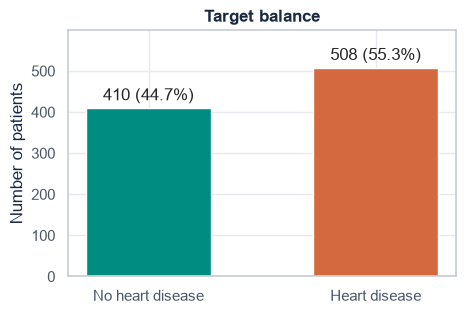

In [8]:
balance = df[C.TARGET].value_counts().sort_index()
balance_tbl = pd.DataFrame({"Class": [C.CLASS_NAMES[i] for i in balance.index],
                            "Patients": balance.values,
                            "%": (balance.values / len(df) * 100).round(1)})
display(balance_tbl)

fig, ax = plt.subplots(figsize=(5, 3.2))
bars = ax.bar(balance_tbl["Class"], balance_tbl["Patients"],
              color=[C.CLASS_COLORS[0], C.CLASS_COLORS[1]], width=0.55)
ax.bar_label(bars, labels=[f"{n} ({p}%)" for n, p in zip(balance_tbl["Patients"], balance_tbl["%"])], padding=3)
ax.set_ylabel("Number of patients")
ax.set_title("Target balance")
ax.set_ylim(0, balance.max() * 1.18)
plots.save_fig(fig, "01_target_balance")
plt.show()

## 6. Data formats: CSV vs JSON
Our dataset is stored as **CSV** (comma-separated values): a flat table, one row per patient. Another very common format
is **JSON** (JavaScript Object Notation): text made of `{"key": value}` pairs and `[lists]`. JSON can store **nested**
structures, which a flat CSV cannot, and it is the standard format for web APIs and configuration files.
This project itself uses JSON: notebook 07 saves all model results to `models/metrics.json`, which the Streamlit app reads.

First we convert the first three patients to JSON text (one object per patient):

In [9]:
import json
records_json = df.head(3).to_json(orient="records", indent=2)
print(records_json)

[
  {
    "Age":40,
    "Sex":"M",
    "ChestPainType":"ATA",
    "RestingBP":140,
    "Cholesterol":289,
    "FastingBS":0,
    "RestingECG":"Normal",
    "MaxHR":172,
    "ExerciseAngina":"N",
    "Oldpeak":0.0,
    "ST_Slope":"Up",
    "HeartDisease":0
  },
  {
    "Age":49,
    "Sex":"F",
    "ChestPainType":"NAP",
    "RestingBP":160,
    "Cholesterol":180,
    "FastingBS":0,
    "RestingECG":"Normal",
    "MaxHR":156,
    "ExerciseAngina":"N",
    "Oldpeak":1.0,
    "ST_Slope":"Flat",
    "HeartDisease":1
  },
  {
    "Age":37,
    "Sex":"M",
    "ChestPainType":"ATA",
    "RestingBP":130,
    "Cholesterol":283,
    "FastingBS":0,
    "RestingECG":"ST",
    "MaxHR":98,
    "ExerciseAngina":"N",
    "Oldpeak":0.0,
    "ST_Slope":"Up",
    "HeartDisease":0
  }
]


Next we save JSON to a file and read it back two ways: with Python's built-in `json` module (gives dictionaries/lists)
and with `pd.read_json` (gives a DataFrame again).

In [10]:
C.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
json_path = C.PROCESSED_DIR / "sample_patients.json"
df.head(5).to_json(json_path, orient="records", indent=2)

with open(json_path, encoding="utf-8") as f:
    loaded = json.load(f)                       # list of Python dictionaries
print("Type:", type(loaded).__name__, "| patients:", len(loaded))
print("First patient's age and cholesterol:", loaded[0]["Age"], loaded[0]["Cholesterol"])

back = pd.read_json(json_path)
print("Round trip identical to the original rows:", back.equals(df.head(5)))

Type: list | patients: 5
First patient's age and cholesterol: 40 289
Round trip identical to the original rows: True


JSON can also hold **nested** data, e.g. a patient record with a sub-object for vital signs and a list of symptoms.
`pd.json_normalize` flattens such a record into table columns (`vitals.RestingBP`, ...):

In [11]:
nested = {
    "patient_id": 1,
    "demographics": {"age": 40, "sex": "M"},
    "vitals": {"RestingBP": 140, "Cholesterol": 289, "MaxHR": 172},
    "symptoms": ["atypical angina"],
}
print(json.dumps(nested, indent=2))
pd.json_normalize(nested)

{
  "patient_id": 1,
  "demographics": {
    "age": 40,
    "sex": "M"
  },
  "vitals": {
    "RestingBP": 140,
    "Cholesterol": 289,
    "MaxHR": 172
  },
  "symptoms": [
    "atypical angina"
  ]
}


,patient_id,symptoms,demographics.age,demographics.sex,vitals.RestingBP,vitals.Cholesterol,vitals.MaxHR
0,1,[atypical angina],40,M,140,289,172


## 7. Save a cleaned copy
We save a copy where the impossible zeros are replaced with `NaN` (missing). Later notebooks load this file.
The raw file `data/heart.csv` is never changed.

In [12]:
C.PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
clean = data.zeros_to_nan(df)
clean.to_csv(C.PROCESSED_DIR / "heart_clean.csv", index=False)
print("Saved:", (C.PROCESSED_DIR / "heart_clean.csv").relative_to(C.ROOT))
print("Missing values after marking zeros:", clean.isna().sum()[clean.isna().sum() > 0].to_dict())

Saved: data\processed\heart_clean.csv


Missing values after marking zeros: {'RestingBP': 1, 'Cholesterol': 172}


## Key Findings
* The dataset has **918 patients and 12 columns** (11 features + 1 target) with **no empty cells** and **no duplicate rows**.
* There are **5 continuous** features (Age, RestingBP, Cholesterol, MaxHR, Oldpeak) and **6 categorical** ones
  (Sex, ChestPainType, FastingBS, RestingECG, ExerciseAngina, ST_Slope).
* **Hidden missing values:** 172 patients (18.7%) have Cholesterol = 0 and 1 patient has RestingBP = 0. These are impossible
  values, so they are treated as missing (handled in notebooks 05 and 06).
* The target is **fairly balanced**: 508 patients (55.3%) have heart disease and 410 (44.7%) do not, so accuracy is
  meaningful, but we will still report precision, recall and F1.
* The sample is **79% male** (725 M vs 193 F) - an important bias discussed in notebook 08.
* The data is stored as **CSV**; we also showed the **JSON** format (records, file round trip, nested objects with `json_normalize`), which the project uses for `models/metrics.json`.